# Capital Bikeshare summer 2026 inspection

June, July, and August 2026. Raw records are unchanged. Set REBUILD=True to rerun the complete inspection. Otherwise this notebook displays the saved diagnostics. Read README.md for findings, definitions, and month-boundary limitations.

In [1]:
from pathlib import Path
import sys, json
import pandas as pd
ROOT=Path.cwd().resolve()
if ROOT.name=='notebooks': ROOT=ROOT.parent
assert (ROOT/'src/inspect_data.py').exists()
sys.path.insert(0,str(ROOT/'src'))
from inspect_data import inspect_data
REBUILD=False
if REBUILD: inspect_data(ROOT)
summary=pd.read_csv(ROOT/'reports/monthly_quality_summary.csv')
print('Total records:',format(summary.trip_records.sum(),','))

Total records: 1,955,497


## Monthly quality summary

In [2]:
print(summary[['month','trip_records','missing_start_station_ids','missing_end_station_ids','duplicate_ride_id_excess_rows']].to_string(index=False))

 month  trip_records  missing_start_station_ids  missing_end_station_ids  duplicate_ride_id_excess_rows
202606        655744                      94394                    99597                              0
202607        653671                      94235                    98978                              0
202608        646082                      87607                    91949                              0


## Timestamp coverage
Monthly archives appear organized by trip end date. Inspect September before claiming complete August departure coverage.

In [3]:
print(summary[['month','earliest_start','latest_start','earliest_end','latest_end','starts_outside_source_month']].to_string(index=False))

 month             earliest_start               latest_start               earliest_end                 latest_end  starts_outside_source_month
202606 2026-05-31 00:18:36.233000 2026-06-30 23:54:26.159000 2026-06-01 00:00:11.185000 2026-06-30 23:59:39.842000                          117
202607 2026-06-29 23:32:05.999000 2026-07-31 23:59:09.111000 2026-07-01 00:00:11.080000 2026-07-31 23:59:54.528000                           69
202608 2026-07-30 23:04:16.142000 2026-08-31 23:51:53.486000 2026-08-01 00:00:04.284000 2026-08-31 23:59:14.797000                          163


## Missing values and station labels

In [4]:
missing=pd.read_csv(ROOT/'reports/missing_values_by_column.csv')
print(missing[missing.missing_count>0].to_string(index=False))
stations=pd.read_csv(ROOT/'reports/station_id_name_inventory.csv',dtype={'station_id':'string'})
print(stations[stations.names_for_this_id>1].to_string(index=False))

 month             column  missing_count  missing_percent
202606 start_station_name          94394        14.394947
202606   start_station_id          94394        14.394947
202606   end_station_name          99331        15.147832
202606     end_station_id          99597        15.188397
202606            end_lat            483         0.073657
202606            end_lng            483         0.073657
202607 start_station_name          94235        14.416274
202607   start_station_id          94235        14.416274
202607   end_station_name          98783        15.112036
202607     end_station_id          98978        15.141868
202607            end_lat            441         0.067465
202607            end_lng            441         0.067465
202608 start_station_name          87607        13.559734
202608   start_station_id          87607        13.559734
202608   end_station_name          91850        14.216462
202608     end_station_id          91949        14.231785
202608        

## Schema and sample
The sample contains the first 10 trips from each archive; it is not representative.

In [5]:
print((ROOT/'reports/schemas.json').read_text())
sample=pd.read_csv(ROOT/'reports/sample_trips.csv',dtype='string')
print(sample.head(3).to_string(index=False))

{
  "202606": {
    "columns": [
      "ride_id",
      "rideable_type",
      "started_at",
      "ended_at",
      "start_station_name",
      "start_station_id",
      "end_station_name",
      "end_station_id",
      "start_lat",
      "start_lng",
      "end_lat",
      "end_lng",
      "member_casual"
    ],
    "read_policy": "All raw fields loaded as strings; blank or whitespace-only fields counted as missing."
  },
  "202607": {
    "columns": [
      "ride_id",
      "rideable_type",
      "started_at",
      "ended_at",
      "start_station_name",
      "start_station_id",
      "end_station_name",
      "end_station_id",
      "start_lat",
      "start_lng",
      "end_lat",
      "end_lng",
      "member_casual"
    ],
    "read_policy": "All raw fields loaded as strings; blank or whitespace-only fields counted as missing."
  },
  "202608": {
    "columns": [
      "ride_id",
      "rideable_type",
      "started_at",
      "ended_at",
      "start_station_name",
      "st

## Calendar and global checks

In [6]:
calendar=pd.read_csv(ROOT/'reports/study_calendar.csv')
print(calendar.groupby(['month','day_type']).size().unstack().to_string())
print((ROOT/'reports/overview.json').read_text())
assert summary.trip_records.sum()==1955497
assert len(calendar)==92
assert summary.duplicate_ride_id_excess_rows.sum()==0

day_type  weekday  weekend
month                     
202606         22        8
202607         23        8
202608         21       10
{
  "total_records": 1955497,
  "same_column_names_and_order": true,
  "global_duplicate_ride_id_excess_rows": 0,
  "cross_month_duplicate_excess_rows": 0,
  "station_ids_with_multiple_names": 5,
  "station_names_with_multiple_ids": 0,
  "unique_nonblank_station_ids_with_names": 870,
  "no_records_modified_or_removed": true
}


## Next steps
Agree on missing-endpoint handling, review station-name mappings, and resolve the summer boundary. Then calculate arrivals and departures at their respective timestamps. Trip records do not measure available bikes or redistribution impact so far.

## Study Window Boundry

In [7]:
import zipfile
import pandas as pd

MONTHS = ['202606', '202607', '202608']
WINDOW_START = pd.Timestamp('2026-06-01')
WINDOW_END   = pd.Timestamp('2026-09-01')   # exclusive

# Only the columns needed for boundary + hourly flow (keeps memory down)
USECOLS = ['rideable_type', 'started_at', 'ended_at',
           'start_station_id', 'end_station_id', 'member_casual']

frames = []
for month in MONTHS:
    archive = ROOT/'data/raw'/f'{month}-capitalbikeshare-tripdata.zip'
    with zipfile.ZipFile(archive) as z:
        members = [n for n in z.namelist()
                   if n.endswith('.csv') and not n.startswith('__MACOSX/')]
        m = [pd.read_csv(z.open(n), dtype='string', keep_default_na=False,
                         usecols=USECOLS) for n in members]
    f = pd.concat(m, ignore_index=True)
    f['source_month'] = month
    frames.append(f)
trips = pd.concat(frames, ignore_index=True)

trips['started_at'] = pd.to_datetime(trips.started_at, format='mixed', errors='coerce')
trips['ended_at']   = pd.to_datetime(trips.ended_at,   format='mixed', errors='coerce')

# --- Reproduce the boundary counts from cell-05, from raw data ---
print('Starts outside source month (expect 117 / 69 / 163):')
print(trips.assign(
    start_month=trips.started_at.dt.strftime('%Y%m')
).query('start_month != source_month')
 .groupby('source_month').size())

# --- Four independent denominators ---
start_in = (trips.started_at >= WINDOW_START) & (trips.started_at <  WINDOW_END)
end_in   = (trips.ended_at   >= WINDOW_START) & (trips.ended_at   <  WINDOW_END)

departures = trips[start_in]          # filter by started_at
arrivals   = trips[end_in]            # filter by ended_at, independently
contained  = trips[start_in & end_in]

print(f"\nRaw records:                  {len(trips):,}")
print(f"Start in window (departures): {len(departures):,}")
print(f"End   in window (arrivals):   {len(arrivals):,}")
print(f"Fully contained in window:    {len(contained):,}")
print(f"\nMay departures excluded (expect 117): "
      f"{int((trips.started_at < WINDOW_START).sum()):,}")
print("September not downloaded — August departures ending in Sept are unseen.")

Starts outside source month (expect 117 / 69 / 163):
source_month
202606    117
202607     69
202608    163
dtype: int64

Raw records:                  1,955,497
Start in window (departures): 1,955,380
End   in window (arrivals):   1,955,497
Fully contained in window:    1,955,380

May departures excluded (expect 117): 117
September not downloaded — August departures ending in Sept are unseen.


## Hourly flow: heavy vs. light usage patterns

Eligible calendar days:
 is_weekend
False    66
True     26

Weekday top 3 hours (counts): {17: 152040, 18: 133709, 8: 111897}
Weekend top 3 hours (counts): {15: 40416, 14: 39617, 16: 38119}

Weekday top 3 hours (per day): {17: 2304.0, 18: 2026.0, 8: 1695.0}
Weekend top 3 hours (per day): {15: 1554.0, 14: 1524.0, 16: 1466.0}


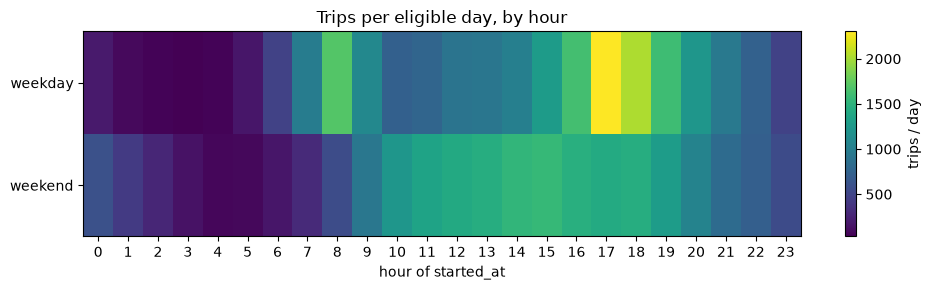


Holiday dates flagged: ['2026-06-19', '2026-07-03', '2026-07-04']
Weekday top 3 hours (holidays removed, counts): {17: 148446, 18: 130808, 8: 110576}


In [9]:
import matplotlib.pyplot as plt

cal = pd.read_csv(ROOT/'reports/study_calendar.csv', parse_dates=['date'],
                  dtype={'holiday_note': 'string'})
cal['is_weekend'] = cal.day_type.eq('weekend')
n_days = cal.groupby('is_weekend').size().rename('eligible_days')
print('Eligible calendar days:\n', n_days.to_string())

dep = departures.copy()
dep['hour']       = dep.started_at.dt.hour
dep['is_weekend'] = dep.started_at.dt.dayofweek.ge(5)

counts  = dep.groupby(['is_weekend', 'hour']).size().unstack(fill_value=0)
per_day = counts.div(n_days, axis=0)

print('\nWeekday top 3 hours (counts):', counts.loc[False].nlargest(3).to_dict())
print('Weekend top 3 hours (counts):', counts.loc[True].nlargest(3).to_dict())
print('\nWeekday top 3 hours (per day):', per_day.loc[False].nlargest(3).round(0).to_dict())
print('Weekend top 3 hours (per day):', per_day.loc[True].nlargest(3).round(0).to_dict())

fig, ax = plt.subplots(figsize=(10, 3))
im = ax.imshow(per_day.values, aspect='auto', cmap='viridis')
ax.set_yticks([0, 1]); ax.set_yticklabels(['weekday', 'weekend'])
ax.set_xticks(range(24))
ax.set_xlabel('hour of started_at')
ax.set_title('Trips per eligible day, by hour')
fig.colorbar(im, ax=ax, label='trips / day')
plt.tight_layout(); plt.show()

holiday_dates = cal.loc[cal.holiday_note.fillna('').ne(''), 'date']
print('\nHoliday dates flagged:', list(holiday_dates.dt.strftime('%Y-%m-%d')))
dep_no_hol = dep[~dep.started_at.dt.normalize().isin(holiday_dates)]
wk_no_hol  = dep_no_hol[~dep_no_hol.is_weekend]
print('Weekday top 3 hours (holidays removed, counts):',
      wk_no_hol.groupby('hour').size().nlargest(3).to_dict())